# Lab 07: Momentum and Adaptive Optimization

**Course:** Deep Learning for Computer Vision — 2026  
**Lecture connection:** Lecture 4B

In this lab, you will implement momentum and Adam, inspect
Nesterov momentum, AdaGrad, and RMSProp, and compare update rules
on the same linear-classifier objective.


## 1. Setup

Keep the notebook, `linear_classifier.py`, and the `dlcv2026`
directory together. Run this cell again after editing
`linear_classifier.py`.


In [5]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
import torch

candidate_dirs = [
    Path.cwd(),
    Path.cwd() / "Labs" / "Lab07",
    Path.cwd() / "Lab07",
    Path.cwd()
    / "Deep-Learning-for-Computer-Vision"
    / "Labs"
    / "Lab07",
]
lab_dir = next(
    (
        path.resolve()
        for path in candidate_dirs
        if (path / "linear_classifier.py").is_file()
        and (path / "dlcv2026").is_dir()
    ),
    None,
)
if lab_dir is None:
    raise FileNotFoundError(
        "Could not find the Lab07 support files. Keep linear_classifier.py "
        "and the dlcv2026 folder together with the notebook."
    )

if str(lab_dir) not in sys.path:
    sys.path.insert(0, str(lab_dir))
for module_name in tuple(sys.modules):
    if (
        module_name == "linear_classifier"
        or module_name == "dlcv2026"
        or module_name.startswith("dlcv2026.")
    ):
        del sys.modules[module_name]

import dlcv2026
import linear_classifier

importlib.reload(linear_classifier)

torch.set_default_dtype(torch.float64)
torch.manual_seed(0)

print("PyTorch:", torch.__version__)
print("Lab directory:", lab_dir)
print("Implementation:", Path(linear_classifier.__file__).resolve())


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
PyTorch: 2.11.0+cu128
Lab directory: /home/pineapple/Coding/PYTHON/nazih/DeepLearningComputerVision/Lab07
Implementation: /home/pineapple/Coding/PYTHON/nazih/DeepLearningComputerVision/Lab07/linear_classifier.py


## 2. SGD baseline

Every update rule receives the current weights, a gradient, and a
configuration dictionary. Plain SGD applies

$$
W_{t+1} = W_t - \eta g_t.
$$


In [6]:
importlib.reload(linear_classifier)

W_example = torch.tensor([1.0, -2.0])
gradient_example = torch.tensor([0.5, -0.25])
W_sgd, _ = linear_classifier.sgd_update(
    W_example,
    gradient_example,
    {"learning_rate": 0.1},
)
print("SGD result:", W_sgd)
assert torch.allclose(W_sgd, torch.tensor([0.95, -1.975]))


SGD result: tensor([ 0.9500, -1.9750])


## 3. Exercise 1 — Momentum

Complete `sgd_momentum_update` using

$$
v_t = \rho v_{t-1} - \eta g_t,
\qquad
W_{t+1} = W_t + v_t.
$$

The velocity must be stored in `config` so the next call can reuse
it.


In [7]:
importlib.reload(linear_classifier)

config = {"learning_rate": 0.1, "momentum": 0.9}
W_first, config = linear_classifier.sgd_momentum_update(
    W_example, gradient_example, config
)
W_second, config = linear_classifier.sgd_momentum_update(
    W_first, gradient_example, config
)

print("after one step:", W_first)
print("after two steps:", W_second)
print("velocity:", config["velocity"])
assert torch.allclose(W_first, torch.tensor([0.95, -1.975]))
assert torch.allclose(W_second, torch.tensor([0.855, -1.9275]))
assert torch.allclose(
    config["velocity"], torch.tensor([-0.095, 0.0475])
)


after one step: tensor([ 0.9500, -1.9750])
after two steps: tensor([ 0.8550, -1.9275])
velocity: tensor([-0.0950,  0.0475])


## 4. Momentum on a poorly conditioned objective

The vertical direction of this quadratic is much steeper than the
horizontal direction. Compare the paths followed by SGD and
momentum from the same starting point.


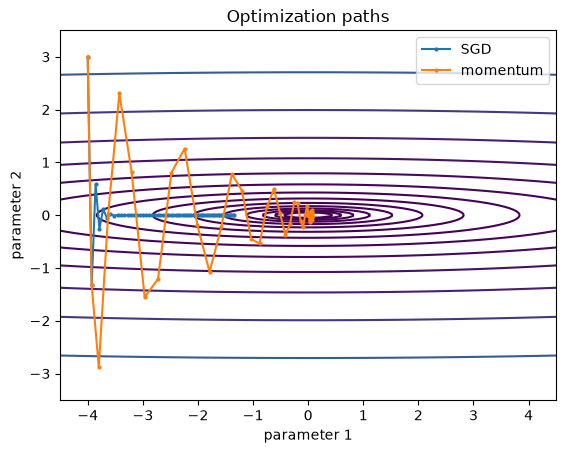

In [8]:
def quadratic_gradient(position):
    return torch.stack((position[0], 80.0 * position[1]))


def optimizer_path(update_rule, config, steps=60):
    position = torch.tensor([-4.0, 3.0])
    path = [position.clone()]
    for _ in range(steps):
        position, config = update_rule(
            position, quadratic_gradient(position), config
        )
        path.append(position.clone())
    return torch.stack(path)


sgd_path = optimizer_path(
    linear_classifier.sgd_update,
    {"learning_rate": 0.018},
)
momentum_path = optimizer_path(
    linear_classifier.sgd_momentum_update,
    {"learning_rate": 0.018, "momentum": 0.8},
)

x_grid = torch.linspace(-4.5, 4.5, 240)
y_grid = torch.linspace(-3.5, 3.5, 240)
grid_x, grid_y = torch.meshgrid(x_grid, y_grid, indexing="xy")
objective = 0.5 * (grid_x**2 + 80.0 * grid_y**2)

plt.contour(
    grid_x,
    grid_y,
    objective,
    levels=torch.logspace(-1, 3, 16),
)
plt.plot(sgd_path[:, 0], sgd_path[:, 1], "o-", ms=2, label="SGD")
plt.plot(
    momentum_path[:, 0],
    momentum_path[:, 1],
    "o-",
    ms=2,
    label="momentum",
)
plt.xlabel("parameter 1")
plt.ylabel("parameter 2")
plt.title("Optimization paths")
plt.legend()
plt.show()


## 5. Nesterov, AdaGrad, and RMSProp

`nesterov_update` uses the rearranged Nesterov formula from the
lecture. AdaGrad accumulates squared gradients, while RMSProp uses
an exponentially decaying average:

$$
r_t^{\text{AdaGrad}} = r_{t-1} + g_t^2,
\qquad
r_t^{\text{RMSProp}} = \rho r_{t-1} + (1-\rho)g_t^2.
$$

All products and divisions in these accumulators are elementwise.


In [9]:
W_adagrad, adagrad_config = linear_classifier.adagrad_update(
    W_example,
    gradient_example,
    {"learning_rate": 0.1},
)
W_rmsprop, rmsprop_config = linear_classifier.rmsprop_update(
    W_example,
    gradient_example,
    {"learning_rate": 0.1, "decay_rate": 0.9},
)
W_nesterov, nesterov_config = linear_classifier.nesterov_update(
    W_example,
    gradient_example,
    {"learning_rate": 0.1, "momentum": 0.9},
)

print("Nesterov result:", W_nesterov)
print("AdaGrad result:", W_adagrad)
print("RMSProp result:", W_rmsprop)
assert (adagrad_config["squared_gradient_sum"] > 0).all()
assert (rmsprop_config["squared_gradient_average"] > 0).all()
assert "velocity" in nesterov_config


Nesterov result: tensor([ 0.9050, -1.9525])
AdaGrad result: tensor([ 0.9000, -1.9000])
RMSProp result: tensor([ 0.6838, -1.6838])


## 6. Exercise 2 — Adam with bias correction

Complete `adam_update`. First update the moment estimates:

$$
m_t = \beta_1 m_{t-1} + (1-\beta_1)g_t,
\qquad
v_t = \beta_2 v_{t-1} + (1-\beta_2)g_t^2.
$$

Then compute $\hat m_t = m_t/(1-\beta_1^t)$ and
$\hat v_t = v_t/(1-\beta_2^t)$ before updating the weights.


In [10]:
importlib.reload(linear_classifier)

adam_config = {
    "learning_rate": 0.01,
    "beta1": 0.9,
    "beta2": 0.999,
    "epsilon": 1e-8,
}
W_adam_first, adam_config = linear_classifier.adam_update(
    W_example, gradient_example, adam_config
)
W_adam_second, adam_config = linear_classifier.adam_update(
    W_adam_first, gradient_example, adam_config
)

print("after one step:", W_adam_first)
print("after two steps:", W_adam_second)
print("timestep:", adam_config["timestep"])
assert torch.allclose(
    W_adam_first,
    torch.tensor([0.99, -1.99]),
    atol=1e-8,
)
assert torch.allclose(
    W_adam_second,
    torch.tensor([0.98, -1.98]),
    atol=1e-8,
)
assert adam_config["timestep"] == 2


after one step: tensor([ 0.9900, -1.9900])
after two steps: tensor([ 0.9800, -1.9800])
timestep: 2


## 7. Compare update rules on one classifier

Every run uses the same data, initial seed, batch size,
regularization strength, and number of iterations. Learning rates
are set separately because the update rules scale gradients
differently.


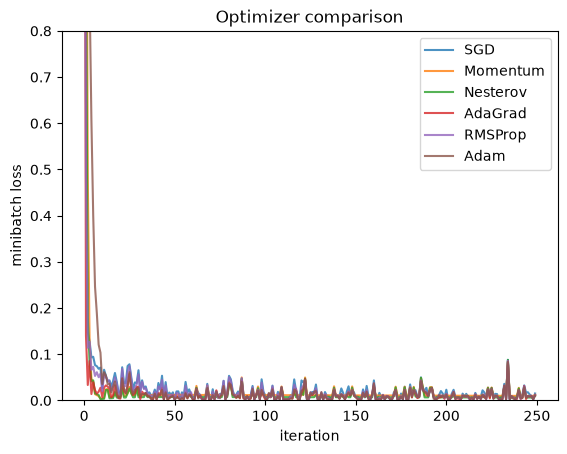

SGD      accuracy=100.00% early_loss=0.1916 late_loss=0.0159
Momentum accuracy=100.00% early_loss=0.2165 late_loss=0.0164
Nesterov accuracy=100.00% early_loss=0.1755 late_loss=0.0138
AdaGrad  accuracy=100.00% early_loss=0.1295 late_loss=0.0131
RMSProp  accuracy=100.00% early_loss=0.1726 late_loss=0.0135
Adam     accuracy=100.00% early_loss=0.3889 late_loss=0.0130


In [11]:
importlib.reload(linear_classifier)
data = dlcv2026.make_toy_classification(seed=11)

experiments = {
    "SGD": (
        linear_classifier.sgd_update,
        {"learning_rate": 0.08},
    ),
    "Momentum": (
        linear_classifier.sgd_momentum_update,
        {"learning_rate": 0.03, "momentum": 0.9},
    ),
    "Nesterov": (
        linear_classifier.nesterov_update,
        {"learning_rate": 0.03, "momentum": 0.9},
    ),
    "AdaGrad": (
        linear_classifier.adagrad_update,
        {"learning_rate": 0.4},
    ),
    "RMSProp": (
        linear_classifier.rmsprop_update,
        {"learning_rate": 0.02, "decay_rate": 0.99},
    ),
    "Adam": (
        linear_classifier.adam_update,
        {"learning_rate": 0.04},
    ),
}

results = {}
for name, (update_rule, config) in experiments.items():
    W, history = linear_classifier.train_linear_classifier(
        linear_classifier.svm_loss_vectorized,
        update_rule,
        data["X_train"],
        data["y_train"],
        optimizer_config=config,
        reg=1e-3,
        num_iters=250,
        batch_size=64,
        seed=5,
    )
    predictions = linear_classifier.predict_linear_classifier(
        W, data["X_val"]
    )
    validation_accuracy = linear_classifier.accuracy(
        predictions, data["y_val"]
    )
    early_loss = sum(history[:20]) / 20
    late_loss = sum(history[-20:]) / 20
    results[name] = (validation_accuracy, early_loss, late_loss)
    plt.plot(history, label=name, alpha=0.8)

plt.ylim(0, 0.8)
plt.xlabel("iteration")
plt.ylabel("minibatch loss")
plt.title("Optimizer comparison")
plt.legend()
plt.show()

for name, (accuracy, early_loss, late_loss) in results.items():
    print(
        f"{name:8s} accuracy={100 * accuracy:6.2f}% "
        f"early_loss={early_loss:.4f} late_loss={late_loss:.4f}"
    )
    assert late_loss < early_loss
    assert accuracy > 0.85


## 8. Wrap-up

Answer briefly in a new Markdown cell:

1. How does momentum reduce oscillation in a steep direction?
2. Why can AdaGrad's effective learning rate become very small?
3. What roles do Adam's first and second moments play?
4. Why must Adam correct the initialization bias of its moments?

-   1. So the main idea is: in a steep direction the gradient alternates sign every step, thus a momentum tries to solve it where in successive gradients with opposite signs cancel each other, while gradients that consistently point the same way (the shallow direction) reinforce each other.
-   2. AdaGrad keeps a running total of every squared gradient it has ever seen, it never shrinks. The step size is scaled down by the square root of that growing total. So if the gradients later become small, the accumulated history stays large, and effective larning rate keeps shrinking towards zero over time. It means learning can slow to a crawl and stall before even model reaches a good solution.
-   3. First momentum is an exponentially decaying average of the gradient. It provides a smoother estimate of the direction of descent, which basically damps noisy updates. Seconds momentum is an exponentially decaying of the squared gradient. The sole role is to estimate the magnitude/scale of the gradient per parameter and use them as a per-parameter normalizer, where giving large steps to parameters with small gradients and small steps to those with large gradients.
-   4. Both of Adam's running averages start at zero, and because the decay rates are close to one, they update very slowly. In the first few steps the averages are therefore pulled heavily towards zero, making them much smaller than the true gradient and its squared magnitude. If left uncorrected, the very first updates would be far too small. The bias correction rescales each average by exactly the amount it has been held back by its zero initialization, so the effective step size is accurate right from the first iteration.